# CSD361 Lab Assignment 1
**Author**: Suryansh Rohil

**User ID**: sr738

**Roll Number**: 2310110314

**Notebook Link**: https://github.com/s-uryansh/CSD361_Intro_To_ML

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({'figure.dpi': 100})
taxi_data = pd.read_csv('Taxi_Trips_-_2024_20240408.csv', low_memory=False)

## I. Initial Dataset Analysis

#### Q1. What are the row and feature counts in this dataset?

In [2]:
print('rows, plot_columns:', taxi_data.shape)

rows, cols: (865247, 23)


**An.**
- Number of rows: 865,247 (`df.shape[0]`).
- Number of features: 23 (`df.shape[1]`).

#### Q2. How are the fields grouped as numeric, categorical, identifiers, or timestamps?

In [3]:
numeric_columns = ['Trip Seconds', 'Trip Miles', 'Pickup Census Tract', 'Dropoff Census Tract',
       'Pickup Community Area', 'Dropoff Community Area', 'Fare', 'Tips', 'Tolls',
       'Extras', 'Trip Total', 'Pickup Centroid Latitude', 'Pickup Centroid Longitude',
       'Dropoff Centroid Latitude', 'Dropoff Centroid Longitude']
categorical_columns = ['Payment Type', 'Company']
identifier_columns = ['Trip ID', 'Taxi ID', 'Pickup Centroid Location', 'Dropoff Centroid  Location']
timestamp_columns = ['Trip Start Timestamp', 'Trip End Timestamp']
print('numerical:', numeric_columns, '\ncategorical:', categorical_columns, '\nidentifiers:', identifier_columns, '\ntimestamps:', timestamp_columns)

numerical: ['Trip Seconds', 'Trip Miles', 'Pickup Census Tract', 'Dropoff Census Tract', 'Pickup Community Area', 'Dropoff Community Area', 'Fare', 'Tips', 'Tolls', 'Extras', 'Trip Total', 'Pickup Centroid Latitude', 'Pickup Centroid Longitude', 'Dropoff Centroid Latitude', 'Dropoff Centroid Longitude'] 
categorical: ['Payment Type', 'Company'] 
identifiers: ['Trip ID', 'Taxi ID', 'Pickup Centroid Location', 'Dropoff Centroid  Location'] 
timestamps: ['Trip Start Timestamp', 'Trip End Timestamp']


**An.** The fields are organized by data type and purpose:
- Numerical (15): Trip Seconds, Trip Miles, Pickup/Dropoff Census Tract, Pickup/Dropoff Community Area, Fare, Tips, Tolls, Extras, Trip Total, Pickup/Dropoff Centroid Latitude/Longitude.
- Categorical (2): Payment Type, Company.
- Identifiers (4): Trip ID, Taxi ID, Pickup/Dropoff Centroid Location.
- Timestamps (2): Trip Start/End Timestamp.

#### Q3. What is the null count for every feature?

In [4]:
print(taxi_data.isna().sum().sort_values(ascending=False).to_string())

Dropoff Census Tract          551393
Pickup Census Tract           537996
Dropoff Community Area         83853
Dropoff Centroid Longitude     79675
Dropoff Centroid  Location     79675
Dropoff Centroid Latitude      79675
Pickup Community Area          23195
Pickup Centroid Location       22966
Pickup Centroid Latitude       22966
Pickup Centroid Longitude      22966
Trip Total                      2045
Fare                            2045
Extras                          2045
Tolls                           2045
Tips                            2045
Trip Seconds                     169
Trip End Timestamp                 8
Trip Miles                         6
Taxi ID                            1
Trip ID                            0
Trip Start Timestamp               0
Payment Type                       0
Company                            0


**An.** Via `df.isna().sum()`:
- Location columns have the most gaps: Dropoff Census Tract (551,393), Pickup Census Tract (537,996), Dropoff Community Area/coords (~80k), Pickup location fields (~23k).
- Target block: Fare/Tips/Tolls/Extras/Trip Total: 2,045 each.
- Nearly complete: Trip Seconds (169), Trip Miles (6); zero missing: Trip ID, Trip Start Timestamp, Payment Type, Company.

#### Q4. Are any complete rows or Trip IDs repeated?

In [5]:
print('duplicate rows:', taxi_data.duplicated().sum(), '| duplicate Trip ID:', taxi_data.duplicated('Trip ID').sum())

duplicate rows: 0 | duplicate Trip ID: 0


**An.**
- Repeated complete rows: 0.
- Repeated Trip IDs: 0.
- Thus, no duplicate entries were detected.

#### Q5. What are the summary statistics for trip_seconds, trip_miles, fare, tips, tolls, extras?

In [6]:
taxi_data[['Trip Seconds', 'Trip Miles', 'Fare', 'Tips', 'Tolls', 'Extras']].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Trip Seconds,865078.0,1150.532018,1584.243513,0.0,459.00,900.00,1591.00,86340.00
Trip Miles,865241.0,6.563330,8.279528,0.0,0.91,3.07,11.71,3093.47
Fare,863202.0,22.057441,25.145823,0.0,8.00,15.75,33.75,9999.75
Tips,863202.0,2.761349,4.132953,0.0,0.00,0.00,4.00,200.00
Tolls,863202.0,0.063232,12.955213,0.0,0.00,0.00,0.00,4444.44
Extras,863202.0,2.149285,19.319780,0.0,0.00,0.00,3.00,5051.10


**An.** Via `describe()` (means above medians indicate positive skew):
- Trip Seconds: mean 1,150.5, median 900, max 86,340.
- Trip Miles: mean 6.56, median 3.07, max 3,093.47.
- Fare: mean 22.06, median 15.75, max 9,999.75.
- Tips/Tolls/Extras: median 0, means 2.76/0.06/2.15, max 200/4,444.44/5,051.10.

#### Q6. What patterns appear in the numeric distributions?

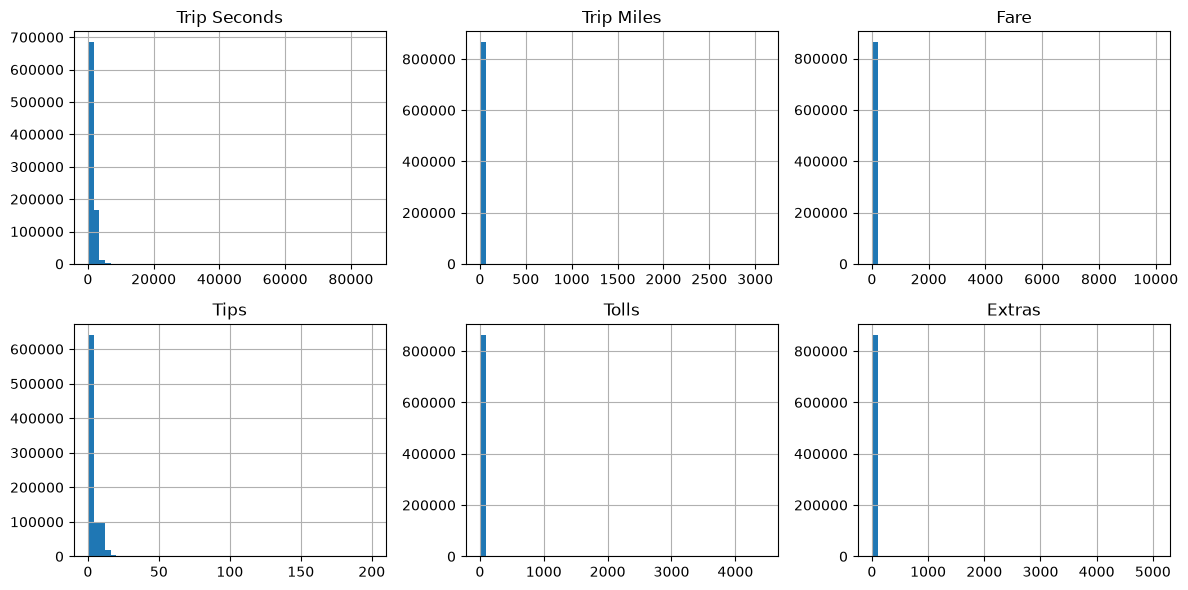

In [7]:
plot_columns = ['Trip Seconds', 'Trip Miles', 'Fare', 'Tips', 'Tolls', 'Extras']
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, c in zip(ax.flat, plot_columns):
    taxi_data[c].dropna().hist(bins=50, ax=a)
    a.set_title(c)
fig.tight_layout()
plt.show()

**An.** The 50-bin histograms show:
- All six cluster at small values and extend through long right tails.
- Tips/Tolls/Extras: sharp pile-up at 0.

## II. Fare Prediction with Linear Regression

#### Q1. Fit a Linear Regression model that estimates Fare.

In [8]:
d = taxi_data.dropna(subset=['Fare']).copy()
d['Trip Start Timestamp'] = pd.to_datetime(d['Trip Start Timestamp'], format='%m/%d/%Y %I:%M:%S %p')
d['Hour'] = d['Trip Start Timestamp'].dt.hour
d['DayOfWeek'] = d['Trip Start Timestamp'].dt.dayofweek
FEATURE_COLUMNS = ['Trip Seconds', 'Trip Miles', 'Pickup Community Area', 'Dropoff Community Area', 'Hour', 'DayOfWeek']
d[FEATURE_COLUMNS] = d[FEATURE_COLUMNS].fillna(d[FEATURE_COLUMNS].median())  # median fill for community areas
X, y = d[FEATURE_COLUMNS].to_numpy(float), d['Fare'].to_numpy(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train, test:', X_train.shape, X_test.shape)
base = LinearRegression().fit(X_train, y_train)
print('MAE %.3f MSE %.3f' % (mean_absolute_error(y_test, base.predict(X_test)), mean_squared_error(y_test, base.predict(X_test))))

train, test: (690561, 6) (172641, 6)
MAE 4.655 MSE 702.576


**An.**
- The six predictors are Trip Seconds, Trip Miles, Pickup/Dropoff Community Area (median-imputed), Hour, DayOfWeek.
- Training setup: closed-form Linear Regression, 80/20 split (`random_state=42`), 690,561 train / 172,641 test.
- Holdout result: MAE 4.655, MSE 702.576.

#### Q2. What motivated this predictor selection?

In [9]:
print(d[FEATURE_COLUMNS + ['Fare']].corr(numeric_only=True)['Fare'].drop('Fare').sort_values(ascending=False).round(3).to_string())

Trip Miles                0.727
Pickup Community Area     0.345
Trip Seconds              0.314
Dropoff Community Area    0.119
Hour                      0.030
DayOfWeek                 0.022


**An.**
- Trip Miles (r=0.727) and Trip Seconds (r=0.314) directly describe fare-related usage and are known when the trip ends, before payment.
- Pickup (0.345) and Dropoff (0.119) Community Area represent geographic pricing effects and are known at dispatch.
- Hour (0.030) and DayOfWeek (0.022) from the start timestamp give a weak but freely available demand signal.
- Omitted fields: 
    - Tips/Tolls/Extras/Trip Total (known only after payment, hence leakage)
    - IDs, census tracts (60%+ missing), \
    - lat/lon (redundant with community area, high missingness), and 
    - Payment Type/Company (post-trip, non-causal).

## III. Compare Three Regression Variants

#### Q1. Fit regressors using raw, Min-Max-scaled, and standardized inputs.

In [10]:
minmax_scaler, standard_scaler = MinMaxScaler().fit(X_train), StandardScaler().fit(X_train)  # fit on train only
feature_sets = {'Original': (X_train, X_test), 'Min-Max': (minmax_scaler.transform(X_train), minmax_scaler.transform(X_test)),
          'Standardized': (standard_scaler.transform(X_train), standard_scaler.transform(X_test))}
fitted_models, metric_results = {}, {}
for name, (a, b) in feature_sets.items():
    m = LinearRegression().fit(a, y_train)
    fitted_models[name] = (m, b)
    metric_results[name] = (mean_absolute_error(y_test, m.predict(b)), mean_squared_error(y_test, m.predict(b)))
print('trained:', list(fitted_models))

trained: ['Original', 'Min-Max', 'Standardized']


**An.**

Three least-squares models were fitted; only their feature representation differs.

#### Q2. Which MAE and MSE does each variant achieve?

In [11]:
print(pd.DataFrame(metric_results, index=['MAE', 'MSE']).T.round(4).to_string())

                 MAE      MSE
Original      4.6553  702.576
Min-Max       4.6553  702.576
Standardized  4.6553  702.576


**An.** The identical holdout set gives:
| Model | MAE | MSE |
|---|---|---|
| Original | 4.6553 | 702.576 |
| Min-Max | 4.6553 | 702.576 |
| Standardized | 4.6553 | 702.576 |

#### Q3. Does scaling alter either error measure?

In [12]:
m = pd.DataFrame(metric_results, index=['MAE', 'MSE']).T
print((m - m.loc['Original']).to_string())  # deviation from Original

                       MAE  MSE
Original      0.000000e+00  0.0
Min-Max      -2.131628e-13  0.0
Standardized -3.552714e-15  0.0


**An.**
- No; both metrics match to four decimal places.
- Deviations ~1e-13: floating-point noise only.

#### Q4. Why do the three variants produce nearly equal predictions?

In [13]:
p0 = fitted_models['Original'][0].predict(X_test)
for n, (m, b) in fitted_models.items():
    print('%s max|pred diff| vs Original: %.2e' % (n, np.abs(m.predict(b) - p0).max()))

Original max|pred diff| vs Original: 0.00e+00
Min-Max max|pred diff| vs Original: 6.99e-12
Standardized max|pred diff| vs Original: 1.36e-12


**An.**
- Yes — predictions agree to ~1e-11.
- Ordinary least squares absorbs linear input scaling into its coefficients.

#### Q5. Which variant is preferable, and why?

In [14]:
a = standard_scaler.transform(X_train)
print('standardized mean:', a.mean(0).round(6))
print('standardized std :', a.std(0).round(6))

standardized mean: [ 0.  0. -0.  0.  0.  0.]
standardized std : [1. 1. 1. 1. 1. 1.]


**An.**
- The standardized variant is recommended.
- Same accuracy, but zero-mean/unit-variance needed for stable gradient descent and regularization.

## IV. Scaling Effects on Gradient Descent

#### Q1. Using one learning rate, plot MSE against iteration for every representation.

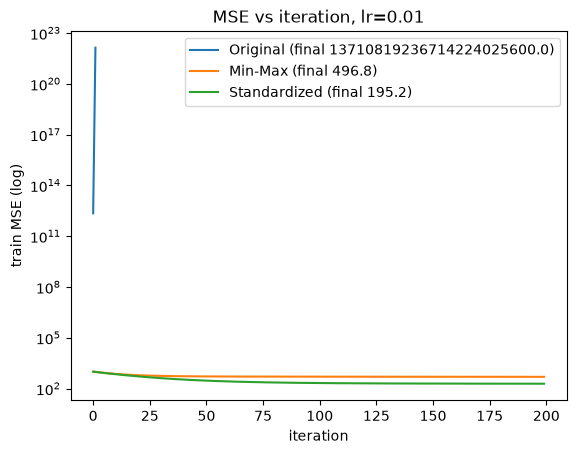

In [15]:
def gradient_descent(X, y, lr=0.01, iters=200):
    """Batch gradient descent for MSE with intercept.

    Args:
        X: feature matrix (n, d).
        y: target vector (n,).
        lr: learning rate.
        iters: number of iterations.

    Returns:
        History of train MSE per iteration.
    """
    A = np.c_[np.ones(len(X)), X]
    w = np.zeros(A.shape[1])
    hist = []
    for _ in range(iters):
        w -= lr * (2 / len(X)) * A.T @ (A @ w - y)
        mse = np.mean((A @ w - y) ** 2)
        hist.append(mse if np.isfinite(mse) else np.nan)
        if not np.isfinite(mse) or mse > 1e18:
            hist += [np.nan] * (iters - len(hist))
            break
    return np.asarray(hist)

LR0, IT = 0.01, 200
curves = {n: gradient_descent(a, y_train, LR0, IT) for n, (a, _) in feature_sets.items()}
for n, h in curves.items():
    plt.plot(h, label=f'{n} (final {h[np.isfinite(h)][-1]:.1f})')
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('train MSE (log)')
plt.title(f'MSE vs iteration, lr={LR0}'); plt.legend(); plt.show()

**An.** Starting at zero weights with rate 0.01 for 200 updates:
- Standardized: approaches the optimum.
- Min-Max: improves more slowly.
- Original: diverges.

#### Q2. Compare convergence time, terminal MSE, and learning-rate sensitivity.

In [16]:
opt = mean_squared_error(y_train, LinearRegression().fit(X_train, y_train).predict(X_train))
print('sklearn train MSE (optimum): %.2f' % opt)
for n, h in curves.items():
    ok = np.where(np.isfinite(h) & (h <= 1.05 * opt))[0]
    print('%s: iters to 5%% of optimum: %s | final MSE: %.2f' % (n, ok[0] + 1 if len(ok) else 'never', h[np.isfinite(h)][-1]))

sklearn train MSE (optimum): 193.82
Original: iters to 5% of optimum: never | final MSE: 13710819236714224025600.00
Min-Max: iters to 5% of optimum: never | final MSE: 496.78
Standardized: iters to 5% of optimum: 125 | final MSE: 195.25


**An.**
- (a) Iterations to within 5% of optimum (train MSE 193.82): Standardized 125, Min-Max never in 200 iterations, Original never (diverges).
- (b) Final train MSE: Standardized 195.25 (near optimum), Min-Max 496.78, Original 1.37e22.
- (c) At lr=0.01, Standardized is stable, Min-Max needs a smaller lr or more iterations, and Original is unstable.

#### Q3. For rates from 0.00001 to 0.1, which runs converge, remain slow, or diverge?

                   0.00001       0.00010       0.00100       0.01000       0.10000
Original      2.683183e+21  8.247193e+19  1.370448e+18  1.371082e+22  1.371145e+26
Min-Max       1.035600e+03  9.688000e+02  6.303000e+02  4.968000e+02  4.748000e+02
Standardized  1.035700e+03  9.680000e+02  5.426000e+02  1.952000e+02  1.938000e+02


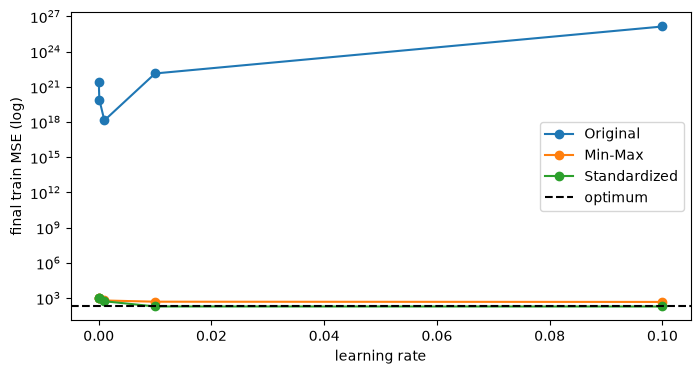

In [17]:
lrs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
grid = pd.DataFrame(index=['Original', 'Min-Max', 'Standardized'], columns=lrs, dtype=float)
for n, (a, _) in feature_sets.items():
    for lr in lrs:
        h = gradient_descent(a, y_train, lr, IT)
        grid.loc[n, lr] = h[np.isfinite(h)][-1] if np.isfinite(h).any() else np.nan
print(grid.round(1).to_string())
grid.T.plot(logy=True, marker='o', figsize=(8, 4))
plt.axhline(opt, color='k', ls='--', label='optimum')
plt.xlabel('learning rate'); plt.ylabel('final train MSE (log)'); plt.legend(); plt.show()

**An.**
- (a) Convergent: Standardized at lr=0.01 (195.2) and lr=0.1 (193.8, ~optimum).
- (b) Slow-moving: lr=1e-5/1e-4 on both scaled sets (~1,036-968 vs optimum 193.8); lr=1e-3 still descending (Min-Max 630.3, Standardized 542.6); Min-Max at 1e-2/1e-1 (496.8/474.8).
- (c) Divergent: Original at all five rates (final MSE 1e18-1e26); it needs a far smaller lr.

#### Q4. Why does normalization alter gradient-descent behavior?

In [18]:
for n, (a, _) in feature_sets.items():
    print('%s cond(X): %.2e' % (n, np.linalg.cond(np.c_[np.ones(len(a)), a])) )

Original cond(X): 7.29e+03
Min-Max cond(X): 5.91e+02
Standardized cond(X): 1.81e+00


**An.**
- The raw objective is poorly conditioned: cond 7.29e3 vs 1.81 standardized.
- One lr is too big for large-scale directions, too small for others.
- Standardized contours near-spherical → lr 0.01–0.1 converges.

## V. Outliers and Normalization

#### Q1. Which values appear extreme for trip_seconds, trip_miles, and fare.

       Trip Seconds  Trip Miles    Fare
0.990        3865.0       26.36   72.25
0.995        4500.0       30.76   83.25
0.999       11341.6       43.55  129.00


/tmp/ipykernel_30758/219520251.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a.boxplot(d[c].dropna(), vert=False)
/tmp/ipykernel_30758/219520251.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a.boxplot(d[c].dropna(), vert=False)
/tmp/ipykernel_30758/219520251.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a.boxplot(d[c].dropna(), vert=False)


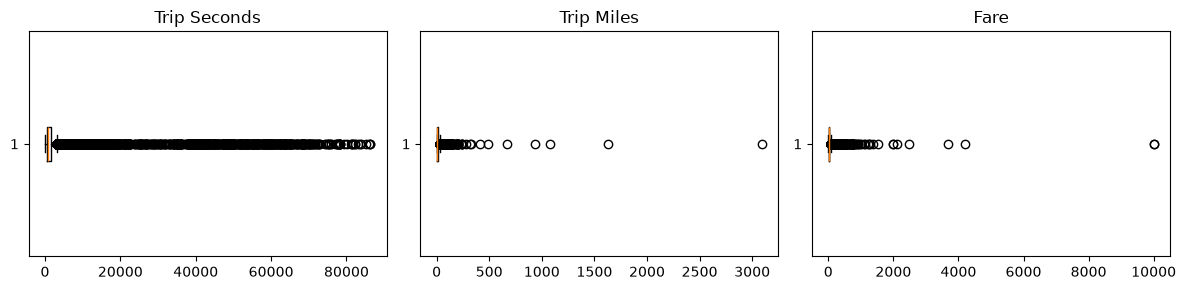

In [19]:
t = ['Trip Seconds', 'Trip Miles', 'Fare']
print(d[t].quantile([0.99, 0.995, 0.999]).round(2).to_string())
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, c in zip(ax, t):
    a.boxplot(d[c].dropna(), vert=False)
    a.set_title(c)
fig.tight_layout()
plt.show()

**An.** The quantiles and boxplots reveal:
- Trip Seconds: 99th 3,865, 99.5th 4,500, 99.9th 11,341.6 (max 86,340).
- Trip Miles: 99th 26.36, 99.5th 30.76, 99.9th 43.55 (max 3,093.47).
- Fare: 99th 72.25, 99.5th 83.25, 99.9th 129.00 (max 9,999.75).

#### Q2. Fit Linear Regression on original data and on data with extreme values removed.

In [20]:
thr = {'Trip Seconds': np.nanquantile(X_train[:, 0], 0.995), 'Trip Miles': np.nanquantile(X_train[:, 1], 0.995),
       'Fare': np.nanquantile(y_train, 0.995)}
keep = (X_train[:, 0] <= thr['Trip Seconds']) & (X_train[:, 1] <= thr['Trip Miles']) & (y_train <= thr['Fare'])
print('thresholds:', {k: round(v, 2) for k, v in thr.items()}, '| removed: %.2f%%' % (100 * (1 - keep.mean())))
out = {}
for name, mask in [('A-original', np.ones(len(y_train), bool)), ('B-filtered', keep)]:
    m = LinearRegression().fit(X_train[mask], y_train[mask])
    out[name] = (mean_absolute_error(y_test, m.predict(X_test)), mean_squared_error(y_test, m.predict(X_test)))
print(pd.DataFrame(out, index=['MAE', 'MSE']).T.round(4).to_string())  # same test set

thresholds: {'Trip Seconds': np.float64(4500.0), 'Trip Miles': np.float64(30.79), 'Fare': np.float64(83.25)} | removed: 1.10%
               MAE       MSE
A-original  4.6553  702.5760
B-filtered  4.5056  744.4156


**An.** Dataset B excludes training observations above the 99.5th percentiles (4,500 s / 30.79 mi / $83.25; 1.10% removed) and both models are evaluated on the same test set:
| Dataset | MAE | MSE |
|---|---|---|
| A-original | 4.6553 | 702.576 |
| B-filtered | 4.5056 | 744.4156 |

#### Q3. Must outlier removal improve Linear Regression accuracy?

In [21]:
for name, mask in [('A-original', np.ones(len(y_train), bool)), ('B-filtered', keep)]:
    m = LinearRegression().fit(X_train[mask], y_train[mask])
    print('%s train MSE %.2f | test MSE %.2f' % (name, mean_squared_error(y_train[mask], m.predict(X_train[mask])), mean_squared_error(y_test, m.predict(X_test))))

A-original train MSE 193.82 | test MSE 702.58
B-filtered train MSE 54.76 | test MSE 744.42


**An.**
- No.
- Train MSE: 193.82 → 54.76 (drops).
- Test MSE: 702.58 → 744.42 (worsens); test MAE: 4.66 → 4.51 only.
- The tail carries information about long, costly trips, while squared error penalizes remaining extremes.